<center><h1>Kim_Beomjun_HW8</h1></center>

Name: Beomjun Kim 
<br>
Github Username: valen991693
<br>
USC ID: 4391-4935-38

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from scipy.special import softmax
from scipy.spatial.distance import cdist
from sklearn.metrics.pairwise import rbf_kernel

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
# Load the dataset
df = pd.read_csv("/Users/kim/Desktop/Education/2. Graduate School (USC)/1. USC_Fall 2026/DSCI 552_Machine Learning for Data Science/4. Homeworks/8. Homework 8/Homework 8 Data/wdbc.data", header=None)

# Separate features and target
X = df.iloc[:, 2:]
y = df.iloc[:, 1].map({"B": 0, "M": 1})

# Assign feature names
X.columns = [f"feature_{i}" for i in range(1, 31)]

# Display dataset information
print("Dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts().sort_index())

print("\nMissing values:", X.isnull().sum().sum())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (569, 32)
Feature matrix shape: (569, 30)
Target shape: (569,)

Class distribution:
1
0    357
1    212
Name: count, dtype: int64

Missing values: 0

First five rows:


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### (b) Monte-Carlo Simulation

#### (i) Supervised Learning

,accuracy,precision,recall,f1,auc
split,,,,,
Test,0.9740,0.9784,0.9508,0.9641,0.9942
Train,0.9871,0.9940,0.9714,0.9825,0.9975


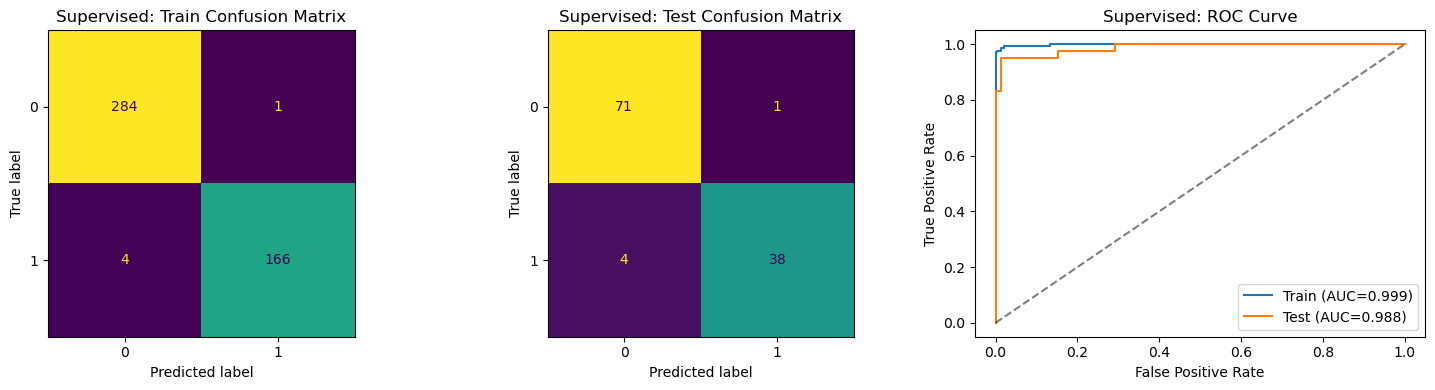

In [3]:
# Shared settings and evaluation helpers
M = 30
C_GRID = np.logspace(-3, 3, 7)
METRICS = ["accuracy", "precision", "recall", "f1", "auc"]

results = []
examples = {}
splits = []


def evaluate(y_true, y_pred, scores):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "auc": roc_auc_score(y_true, scores)
    }


def record(method, run, split, y_true, y_pred, scores):
    results.append({
        "method": method,
        "run": run,
        "split": split,
        **evaluate(y_true, y_pred, scores)
    })

    if run == 0:
        examples[(method, split)] = (
            np.asarray(y_true),
            np.asarray(y_pred),
            np.asarray(scores)
        )


def show_example(method):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for ax, split in zip(axes[:2], ["Train", "Test"]):
        yt, yp, _ = examples[(method, split)]

        ConfusionMatrixDisplay.from_predictions(
            yt, yp, ax=ax, colorbar=False
        )

        ax.set_title(f"{method}: {split} Confusion Matrix")

    for split in ["Train", "Test"]:
        yt, _, scores = examples[(method, split)]

        fpr, tpr, _ = roc_curve(yt, scores)

        axes[2].plot(
            fpr,
            tpr,
            label=f"{split} (AUC={roc_auc_score(yt, scores):.3f})"
        )

    axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)

    axes[2].set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title=f"{method}: ROC Curve"
    )

    axes[2].legend()
    plt.tight_layout()
    plt.show()


def fit_l1_svm(X_train, y_train):
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=50000,
            tol=1e-3, 
            random_state=42
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        pipe,
        {"svm__C": C_GRID},
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    return search.best_estimator_, search.best_params_["svm__C"]


# Generate 30 stratified train/test splits
for run in range(M):
    tr, te = train_test_split(
        np.arange(len(y)),
        test_size=0.2,
        stratify=y,
        random_state=42 + run
    )

    splits.append((tr, te))


# Monte Carlo Simulation
for run, (tr, te) in enumerate(splits):
    model, best_c = fit_l1_svm(
        X.iloc[tr],
        y.iloc[tr]
    )

    for name, idx in [("Train", tr), ("Test", te)]:
        pred = model.predict(X.iloc[idx])
        score = model.decision_function(X.iloc[idx])

        record(
            "Supervised",
            run,
            name,
            y.iloc[idx],
            pred,
            score
        )


# Average performance
supervised_summary = (
    pd.DataFrame(results)
    .query("method == 'Supervised'")
    .groupby("split")[METRICS]
    .mean()
    .round(4)
)

display(supervised_summary)

# Confusion matrices and ROC curves
show_example("Supervised")

#### (ii) Semi-Supervised Learning/ Self-training

##### (A) Train an L1-Penalized SVM

In [4]:
# Select 50% of each class as initially labeled data
initial_sets = []

for run, (tr, te) in enumerate(splits):
    labeled, unlabeled = train_test_split(
        tr,
        train_size=0.5,
        stratify=y.iloc[tr],
        random_state=1000 + run
    )

    initial_sets.append((labeled, unlabeled))


# Train the initial L1-SVM using 5-fold CV
labeled0, unlabeled0 = initial_sets[0]

initial_model, initial_c = fit_l1_svm(
    X.iloc[labeled0],
    y.iloc[labeled0]
)

print("Initially labeled observations:", len(labeled0))
print("Initially unlabeled observations:", len(unlabeled0))
print("Best C in first run:", initial_c)

Initially labeled observations: 227
Initially unlabeled observations: 228
Best C in first run: 0.1


##### (B) Self-Training

,accuracy,precision,recall,f1,auc
split,,,,,
Test,0.9670,0.9690,0.9413,0.9544,0.9908
Train,0.9752,0.9821,0.9514,0.9663,0.9935


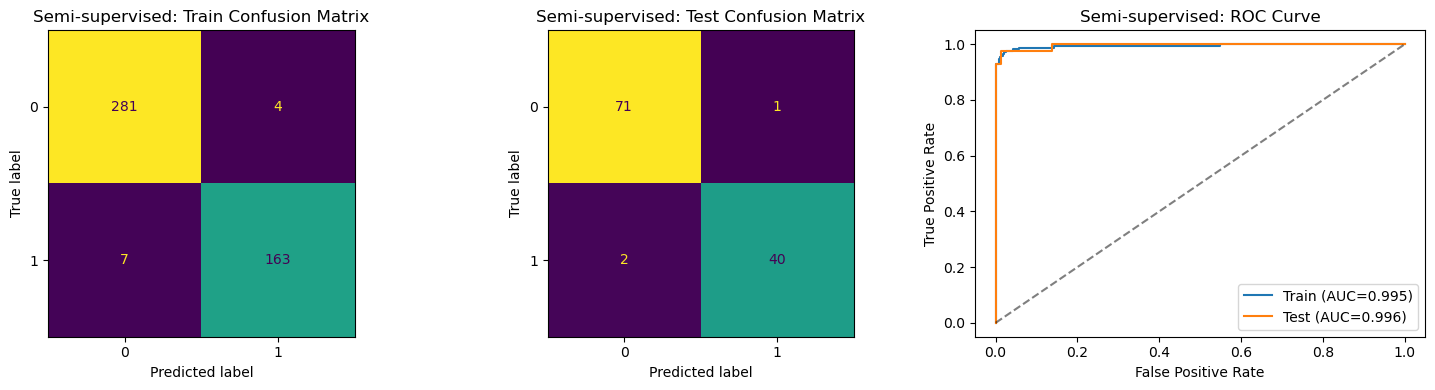

In [5]:
# Semi-supervised self-training
for run, ((tr, te), (labeled, unlabeled)) in enumerate(
    zip(splits, initial_sets)
):

    scaler = StandardScaler().fit(X.iloc[tr])
    X_scaled = scaler.transform(X)

    labeled = list(labeled)
    remaining = list(unlabeled)

    pseudo_y = list(y.iloc[labeled].to_numpy())

    # Select C using 5-fold CV on initially labeled data
    _, best_c = fit_l1_svm(
        X.iloc[labeled],
        y.iloc[labeled]
    )

    model = LinearSVC(
        C=best_c,
        penalty="l1",
        dual=False,
        max_iter=50000,
        tol=1e-3, 
        random_state=42
    )

    # Iteratively label the most confident observation
    while remaining:
        model.fit(X_scaled[labeled], pseudo_y)

        margins = np.abs(
            model.decision_function(X_scaled[remaining])
        )

        chosen_position = int(np.argmax(margins))
        chosen_idx = remaining.pop(chosen_position)

        pseudo_label = int(
            model.predict(X_scaled[[chosen_idx]])[0]
        )

        labeled.append(chosen_idx)
        pseudo_y.append(pseudo_label)

    # Train final model
    model.fit(X_scaled[labeled], pseudo_y)

    # Evaluate training and test performance
    for name, idx in [("Train", tr), ("Test", te)]:
        pred = model.predict(X_scaled[idx])
        score = model.decision_function(X_scaled[idx])

        record(
            "Semi-supervised",
            run,
            name,
            y.iloc[idx],
            pred,
            score
        )


# Average performance
semi_summary = (
    pd.DataFrame(results)
    .query("method == 'Semi-supervised'")
    .groupby("split")[METRICS]
    .mean()
    .round(4)
)

display(semi_summary)

# Confusion matrices and ROC curves
show_example("Semi-supervised")

The semi-supervised learning model achieved a mean test accuracy of 0.9670 and an AUC of 0.9908 across 30 Monte Carlo iterations.

Its performance was slightly lower than that of the supervised model, which achieved a mean test accuracy of 0.9740 and an AUC of 0.9942.

This difference may be attributed to errors introduced during pseudo-labeling, as incorrectly predicted labels can affect subsequent model training.

#### (iii) Unsupervised Learning (K-Means)

##### (A) K-Means Initialization

In [6]:
# K-Means initialization
kmeans_runs = []

for run, (tr, te) in enumerate(splits):

    scaler = StandardScaler().fit(X.iloc[tr])

    xtr = scaler.transform(X.iloc[tr])
    xte = scaler.transform(X.iloc[te])

    km = KMeans(
        n_clusters=2,
        init="random",
        n_init=20,
        random_state=42 + run
    )

    km.fit(xtr)

    kmeans_runs.append((km, xtr, xte))


print(
    "First run inertia:",
    round(kmeans_runs[0][0].inertia_, 4)
)

print("Number of random initializations per run: 20")

First run inertia: 9254.8273
Number of random initializations per run: 20


##### (B) Training Set Evaluation

In [7]:
# Majority voting using 30 nearest observations
kmeans_label_maps = []

for run, ((tr, te), (km, xtr, xte)) in enumerate(
    zip(splits, kmeans_runs)
):

    ytr = y.iloc[tr].to_numpy()

    distances = cdist(
        xtr,
        km.cluster_centers_
    )

    label_map = {}

    for cluster in range(2):
        nearest = np.argsort(
            distances[:, cluster]
        )[:30]

        label_map[cluster] = int(
            np.mean(ytr[nearest]) >= 0.5
        )

    kmeans_label_maps.append(label_map)

    # Predicted labels
    pred = np.array([
        label_map[c] for c in km.labels_
    ])

    # Continuous scores for ROC/AUC
    probs = softmax(-distances, axis=1)

    score = sum(
        probs[:, c]
        for c in range(2)
        if label_map[c] == 1
    )

    record(
        "K-Means",
        run,
        "Train",
        ytr,
        pred,
        score
    )


# Average training performance
kmeans_train_summary = (
    pd.DataFrame(results)
    .query("method == 'K-Means' and split == 'Train'")[METRICS]
    .mean()
    .round(4)
)

display(kmeans_train_summary)

accuracy     0.9099
precision    0.9245
recall       0.8269
f1           0.8727
auc          0.9747
dtype: float64

##### (C) Test Set Evaluation

,accuracy,precision,recall,f1,auc
split,,,,,
Test,0.9135,0.9199,0.8389,0.8764,0.9753
Train,0.9099,0.9245,0.8269,0.8727,0.9747


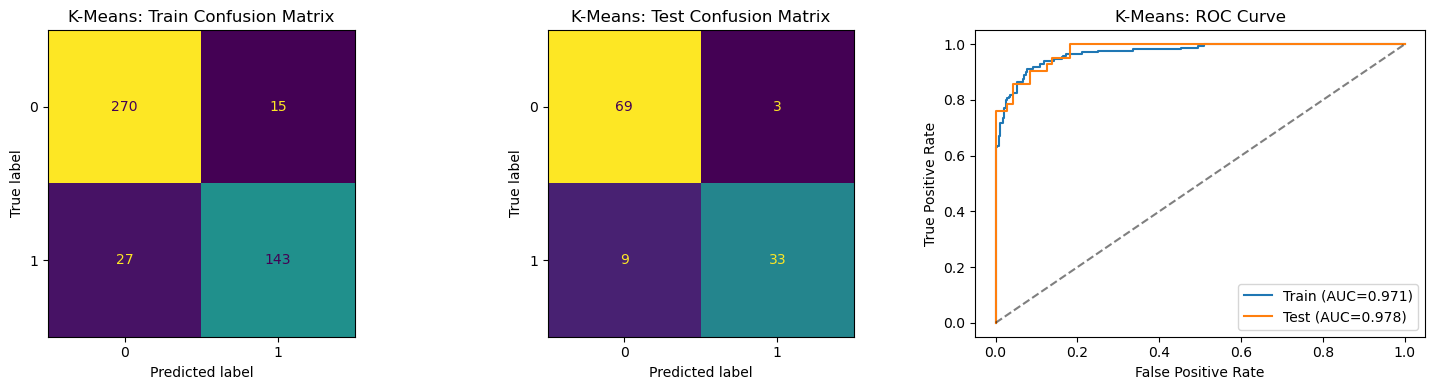

In [8]:
# K-Means test set evaluation
for run, ((tr, te), (km, xtr, xte), label_map) in enumerate(
    zip(splits, kmeans_runs, kmeans_label_maps)
):

    # Predict clusters
    cluster_pred = km.predict(xte)

    # Convert clusters to class labels
    pred = np.array([
        label_map[c] for c in cluster_pred
    ])

    # Compute distances
    distances = cdist(
        xte,
        km.cluster_centers_
    )

    # Continuous scores for ROC/AUC
    probs = softmax(-distances, axis=1)

    score = sum(
        probs[:, c]
        for c in range(2)
        if label_map[c] == 1
    )

    record(
        "K-Means",
        run,
        "Test",
        y.iloc[te],
        pred,
        score
    )


# Average training and test performance
kmeans_summary = (
    pd.DataFrame(results)
    .query("method == 'K-Means'")
    .groupby("split")[METRICS]
    .mean()
    .round(4)
)

display(kmeans_summary)

# Confusion matrices and ROC curves
show_example("K-Means")

#### (iv) Spectral Clustering

In [9]:
# Check cluster balance for different gamma values
tr, te = splits[0]

scaler = StandardScaler()
xtr = scaler.fit_transform(X.iloc[tr])
ytr = y.iloc[tr].to_numpy()

# Actual class distribution
class_counts = np.sort(
    np.bincount(ytr, minlength=2)
)

print("Actual Class Distribution:", class_counts)
print()

gamma_results = []

for gamma in [0.0001, 0.0003, 0.0005, 0.0007, 0.001, 0.003, 0.01, 0.1, 1]:

    spectral = SpectralClustering(
        n_clusters=2,
        affinity="rbf",
        gamma=gamma,
        assign_labels="kmeans",
        n_init=20,
        random_state=42
    )

    clusters = spectral.fit_predict(xtr)

    counts = np.bincount(
        clusters,
        minlength=2
    )

    # Compare cluster sizes with actual class distribution
    difference = np.abs(
        np.sort(counts) - class_counts
    ).sum()

    gamma_results.append({
        "Gamma": gamma,
        "Cluster 0": counts[0],
        "Cluster 1": counts[1],
        "Difference": difference
    })

gamma_results = pd.DataFrame(gamma_results)

display(gamma_results)

# Select gamma with the smallest difference
best_gamma = gamma_results.loc[
    gamma_results["Difference"].idxmin()
]

print("Best Gamma:", best_gamma["Gamma"])
print("Minimum Difference:", best_gamma["Difference"])

Actual Class Distribution: [170 285]



,Gamma,Cluster 0,Cluster 1,Difference
0,0.0001,300,155,30
1,0.0003,300,155,30
2,0.0005,300,155,30
3,0.0007,300,155,30
4,0.0010,300,155,30
5,0.0030,316,139,62
6,0.0100,330,125,90
7,0.1000,453,2,336
8,1.0000,453,2,336


Best Gamma: 0.0001
Minimum Difference: 30.0


##### Gamma Selection

The RBF kernel parameter was evaluated using nine gamma values ranging from 0.0001 to 1 on the first Monte Carlo training split.

The actual class distribution contained 285 and 170 observations. Gamma values from 0.0001 to 0.001 produced clusters containing 300 and 155 observations, resulting in the smallest difference from the actual class distribution among the evaluated values.

In contrast, gamma values of 0.1 and 1 produced highly imbalanced clusters containing 453 and 2 observations.

Therefore, gamma = 0.0001 was selected as the first value achieving the minimum difference in cluster sizes. Although the resulting clusters did not exactly match the actual class distribution, they were the closest among the evaluated gamma values.

,accuracy,precision,recall,f1,auc
split,,,,,
Test,0.8743,0.9780,0.6746,0.7963,0.9716
Train,0.9076,0.9191,0.8257,0.8697,0.9712


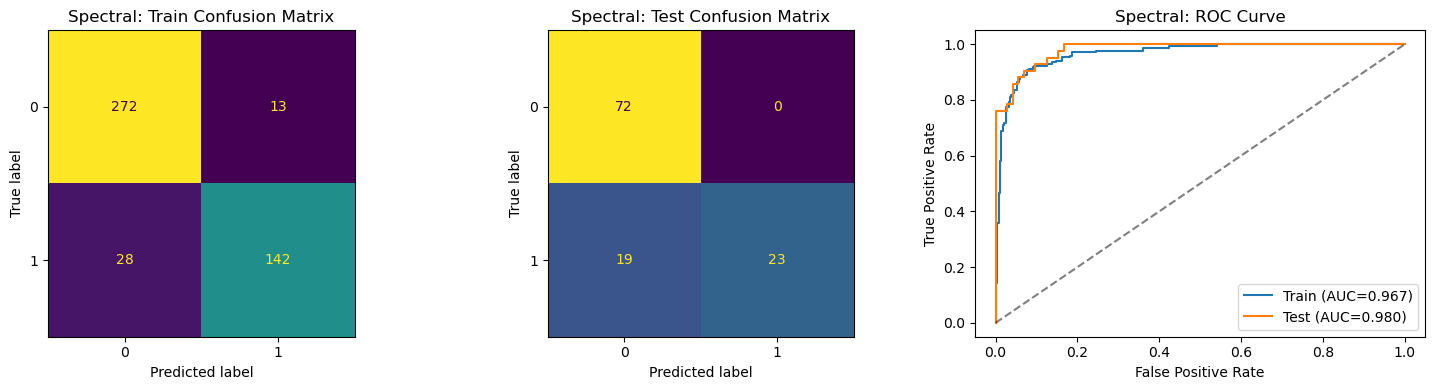

In [10]:
# Spectral clustering with RBF kernel
GAMMA = 0.0001

for run, (tr, te) in enumerate(splits):

    scaler = StandardScaler().fit(X.iloc[tr])

    xtr = scaler.transform(X.iloc[tr])
    xte = scaler.transform(X.iloc[te])

    spectral = SpectralClustering(
        n_clusters=2,
        affinity="rbf",
        gamma=GAMMA,
        assign_labels="kmeans",
        n_init=20,
        random_state=42 + run
    )

    # Fit spectral clustering
    clusters = spectral.fit_predict(xtr)

    ytr = y.iloc[tr].to_numpy()

    # Majority voting
    label_map = {
        c: int(np.mean(ytr[clusters == c]) >= 0.5)
        for c in range(2)
    }

    # Training predictions
    train_pred = np.array([
        label_map[c] for c in clusters
    ])

    # RBF similarity matrices
    Ktr = rbf_kernel(
        xtr,
        xtr,
        gamma=GAMMA
    )

    Kte = rbf_kernel(
        xte,
        xtr,
        gamma=GAMMA
    )

    # Compute affinity-based scores
    def affinity_scores(kernel):

        similarities = np.column_stack([
            kernel[:, clusters == c].mean(axis=1)
            for c in range(2)
        ])

        denom = similarities.sum(axis=1)

        probabilities = similarities / np.maximum(
            denom[:, None],
            1e-12
        )

        positive_score = sum(
            probabilities[:, c]
            for c in range(2)
            if label_map[c] == 1
        )

        return similarities, positive_score

    # Training scores
    _, train_score = affinity_scores(Ktr)

    # Test scores and predictions
    test_similarity, test_score = affinity_scores(Kte)

    test_clusters = np.argmax(
        test_similarity,
        axis=1
    )

    test_pred = np.array([
        label_map[c] for c in test_clusters
    ])

    # Record training performance
    record(
        "Spectral",
        run,
        "Train",
        ytr,
        train_pred,
        train_score
    )

    # Record test performance
    record(
        "Spectral",
        run,
        "Test",
        y.iloc[te],
        test_pred,
        test_score
    )


# Average performance
spectral_summary = (
    pd.DataFrame(results)
    .query("method == 'Spectral'")
    .groupby("split")[METRICS]
    .mean()
    .round(4)
)

display(spectral_summary)

# Confusion matrices and ROC curves
show_example("Spectral")

Since SpectralClustering does not provide a built-in predict() method, test observations were assigned to clusters based on their average RBF similarity to the training observations within each cluster.

Each test observation was assigned to the cluster with the highest average similarity, and the corresponding majority-vote label was used for classification.

This affinity-based assignment serves as an approximation for out-of-sample prediction rather than a direct extension of spectral clustering.

Spectral clustering achieved a mean test accuracy of 0.8743, precision of 0.9780, recall of 0.6746, F1-score of 0.7963, and AUC of 0.9716 across 30 Monte Carlo iterations.

Although the model demonstrated high precision, its relatively low recall indicates that it failed to identify a substantial proportion of malignant cases.

This suggests that the model was relatively conservative in predicting the malignant class.

#### (v) Comparison of Learning Methods

accuracy         precision          recall          \
                          mean     std      mean     std    mean     std   
method          split                                                      
K-Means         Test    0.9135  0.0244    0.9199  0.0336  0.8389  0.0575   
                Train   0.9099  0.0070    0.9245  0.0189  0.8269  0.0185   
Semi-supervised Test    0.9670  0.0194    0.9690  0.0321  0.9413  0.0384   
                Train   0.9752  0.0062    0.9821  0.0142  0.9514  0.0169   
Spectral        Test    0.8743  0.0232    0.9780  0.0220  0.6746  0.0666   
                Train   0.9076  0.0063    0.9191  0.0134  0.8257  0.0159   
Supervised      Test    0.9740  0.0173    0.9784  0.0255  0.9508  0.0330   
                Train   0.9871  0.0042    0.9940  0.0050  0.9714  0.0084   

                           f1             auc          
                         mean     std    mean     std  
method          split                                  
K-Means         Test   0.8764  0.0372  0.9753  0.0107  
                Train  0.8727  0.0101  0.9747  0.0033  
Semi-supervised Test   0.9544  0.0268  0.9908  0.0097  
                Train  0.9663  0.0085  0.9935  0.0026  
Spectral        Test   0.7963  0.0463  0.9716  0.0109  
                Train  0.8697  0.0093  0.9712  0.0032  
Supervised      Test   0.9641  0.0240  0.9942  0.0070  
                Train  0.9825  0.0057  0.9975  0.0011

Mean Test Performance Across 30 Monte Carlo Runs:


,accuracy,precision,recall,f1,auc
method,,,,,
Supervised,0.9740,0.9784,0.9508,0.9641,0.9942
Semi-supervised,0.9670,0.9690,0.9413,0.9544,0.9908
K-Means,0.9135,0.9199,0.8389,0.8764,0.9753
Spectral,0.8743,0.9780,0.6746,0.7963,0.9716


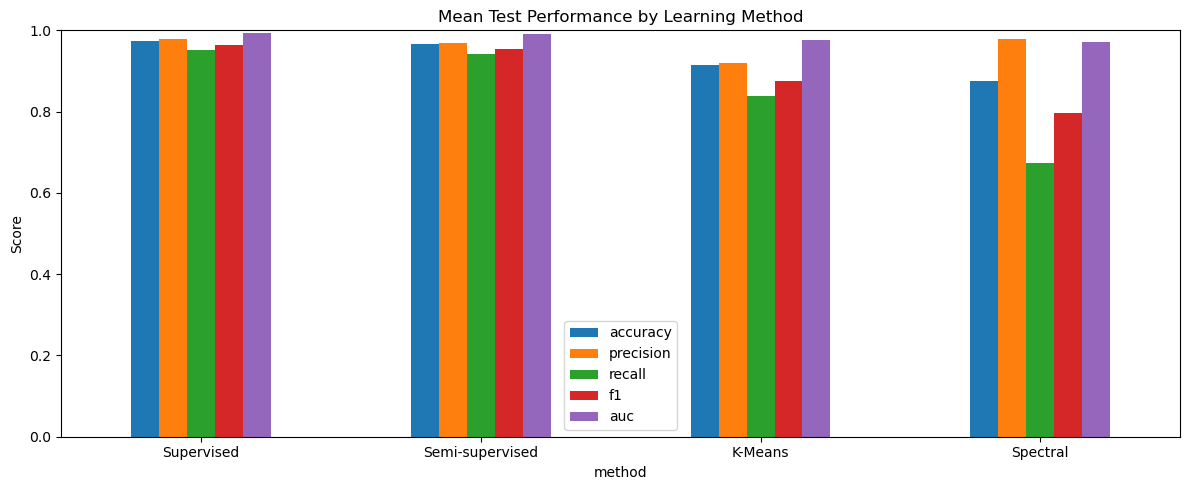

In [11]:
# Summary statistics across 30 Monte Carlo runs
summary = (
    pd.DataFrame(results)
    .groupby(["method", "split"])[METRICS]
    .agg(["mean", "std"])
    .round(4)
)

display(summary)


# Compare average test performance
comparison = (
    pd.DataFrame(results)
    .query("split == 'Test'")
    .groupby("method")[METRICS]
    .mean()
    .sort_values("auc", ascending=False)
    .round(4)
)

print("Mean Test Performance Across 30 Monte Carlo Runs:")
display(comparison)


# Visualize model comparison
comparison.plot(
    kind="bar",
    figsize=(12, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Mean Test Performance by Learning Method")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

##### Discussion

Across 30 Monte Carlo iterations, supervised learning achieved the highest overall predictive performance, with a mean test accuracy of 0.9740, F1-score of 0.9641, and AUC of 0.9942.

Semi-supervised learning performed similarly, achieving a mean test accuracy of 0.9670 and an AUC of 0.9908. However, it did not outperform supervised learning, potentially due to errors introduced during the pseudo-labeling process.

Among the unsupervised methods, K-Means achieved higher accuracy, recall, and F1-score than spectral clustering. Although spectral clustering achieved high precision comparable to supervised learning, its substantially lower recall suggests that it missed more malignant observations.

Overall, supervised learning provided the best performance across most evaluation metrics. Semi-supervised learning was a competitive alternative, while the unsupervised methods showed relatively weaker classification performance.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [12]:
# Load the Banknote Authentication dataset
banknote = pd.read_csv(
    "/Users/kim/Desktop/Education/2. Graduate School (USC)/1. USC_Fall 2026/DSCI 552_Machine Learning for Data Science/4. Homeworks/8. Homework 8/Homework 8 Data/data_banknote_authentication.txt",
    header=None,
    names=["variance", "skewness", "curtosis", "entropy", "class"]
)

# Separate features and target
X_banknote = banknote.drop(columns="class")
y_banknote = banknote["class"]

print("Dataset shape:", banknote.shape)
print("\nClass distribution:")
print(y_banknote.value_counts())

display(banknote.head())

Dataset shape: (1372, 5)

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [13]:
# Passive Learning

RUNS = 50
BATCH_SIZE = 10
TRAIN_SIZE = 900

training_sizes = np.arange(
    BATCH_SIZE,
    TRAIN_SIZE + 1,
    BATCH_SIZE
)

passive_errors = np.zeros(
    (RUNS, len(training_sizes))
)

active_errors = np.zeros(
    (RUNS, len(training_sizes))
)


# Train L1-penalized SVM using 5-fold cross-validation
def fit_banknote_svm(X_train, y_train):

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=100000,
            tol=1e-3,
            random_state=42
        ))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    grid = GridSearchCV(
        pipeline,
        param_grid={
            "svm__C": np.logspace(-3, 1, 5)
        },
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    return grid.best_estimator_


# Select an initial labeled set suitable for 5-fold CV
def get_initial_indices(y_train, rng):

    while True:

        indices = rng.choice(
            len(y_train),
            size=BATCH_SIZE,
            replace=False
        )

        class_counts = np.bincount(
            y_train[indices],
            minlength=2
        )

        if np.all(class_counts >= 5):
            return indices


# Prepare the same data splits for both methods
banknote_splits = []

X_bank = X_banknote.to_numpy()
y_bank = y_banknote.to_numpy()

for run in range(RUNS):

    X_train, X_test, y_train, y_test = train_test_split(
        X_bank,
        y_bank,
        train_size=TRAIN_SIZE,
        stratify=y_bank,
        random_state=42 + run
    )

    rng = np.random.default_rng(1000 + run)

    initial_indices = get_initial_indices(
        y_train,
        rng
    )

    banknote_splits.append((
        X_train,
        X_test,
        y_train,
        y_test,
        initial_indices
    ))

    remaining_indices = np.setdiff1d(
        np.arange(TRAIN_SIZE),
        initial_indices
    )

    random_order = np.concatenate([
        initial_indices,
        rng.permutation(remaining_indices)
    ])

    # Increase labeled training size from 10 to 900
    for step, n_samples in enumerate(training_sizes):

        selected_indices = random_order[:n_samples]

        model = fit_banknote_svm(
            X_train[selected_indices],
            y_train[selected_indices]
        )

        predictions = model.predict(X_test)

        passive_errors[run, step] = (
            1 - accuracy_score(y_test, predictions)
        )


print("Passive Learning Completed")
print("Test Error Matrix Shape:", passive_errors.shape)

print(
    "Mean Final Test Error:",
    round(passive_errors[:, -1].mean(), 4)
)

Passive Learning Completed
Test Error Matrix Shape: (50, 90)
Mean Final Test Error: 0.0104


#### (ii) Active

In [14]:
# Active Learning

for run, (
    X_train,
    X_test,
    y_train,
    y_test,
    initial_indices
) in enumerate(banknote_splits):

    selected_indices = list(initial_indices)

    remaining_indices = np.setdiff1d(
        np.arange(TRAIN_SIZE),
        initial_indices
    ).tolist()

    for step, n_samples in enumerate(training_sizes):

        # Train SVM using currently labeled observations
        model = fit_banknote_svm(
            X_train[selected_indices],
            y_train[selected_indices]
        )

        # Evaluate test error
        predictions = model.predict(X_test)

        active_errors[run, step] = (
            1 - accuracy_score(y_test, predictions)
        )

        # Stop when all 900 observations are labeled
        if step == len(training_sizes) - 1:
            break

        # Compute distances from the decision boundary
        decision_scores = np.abs(
            model.decision_function(
                X_train[remaining_indices]
            )
        )

        # Select 10 observations closest to the boundary
        closest_positions = np.argsort(
            decision_scores
        )[:BATCH_SIZE]

        new_indices = [
            remaining_indices[i]
            for i in closest_positions
        ]

        # Add selected observations to the labeled set
        selected_indices.extend(new_indices)

        # Remove selected observations from the unlabeled pool
        selected_set = set(new_indices)

        remaining_indices = [
            idx
            for idx in remaining_indices
            if idx not in selected_set
        ]


print("Active Learning Completed")
print("Test Error Matrix Shape:", active_errors.shape)

print(
    "Mean Final Test Error:",
    round(active_errors[:, -1].mean(), 4)
)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/opt/anaconda3/lib/python3.11/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the n

Active Learning Completed
Test Error Matrix Shape: (50, 90)
Mean Final Test Error: 0.0104


### (c) Average the 50 test errors

,Training Size,Passive Test Error,Active Test Error
0,10,0.1328,0.1328
1,20,0.0657,0.0629
2,30,0.0409,0.0392
3,40,0.0284,0.0237
4,50,0.0264,0.0182
...,...,...,...
85,860,0.0103,0.0104
86,870,0.0104,0.0106
87,880,0.0104,0.0104
88,890,0.0106,0.0105


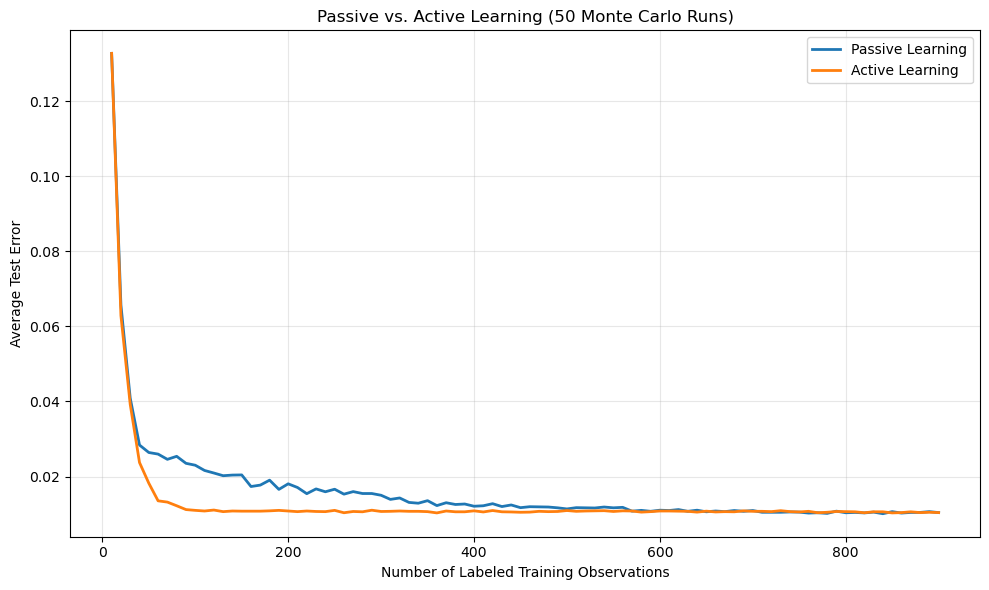

Average Test Error Across All Training Sizes
Passive Learning: 0.0161
Active Learning: 0.0132

Final Test Error (900 Training Observations)
Passive Learning: 0.0104
Active Learning: 0.0104


In [15]:
# Average test errors across 50 Monte Carlo simulations

passive_mean = passive_errors.mean(axis=0)
active_mean = active_errors.mean(axis=0)


# Create comparison DataFrame
learning_comparison = pd.DataFrame({
    "Training Size": training_sizes,
    "Passive Test Error": passive_mean,
    "Active Test Error": active_mean
})

display(learning_comparison.round(4))


# Plot learning curves
plt.figure(figsize=(10, 6))

plt.plot(
    training_sizes,
    passive_mean,
    label="Passive Learning",
    linewidth=2
)

plt.plot(
    training_sizes,
    active_mean,
    label="Active Learning",
    linewidth=2
)

plt.xlabel("Number of Labeled Training Observations")
plt.ylabel("Average Test Error")
plt.title("Passive vs. Active Learning (50 Monte Carlo Runs)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Summary statistics
print("Average Test Error Across All Training Sizes")

print(
    "Passive Learning:",
    round(passive_mean.mean(), 4)
)

print(
    "Active Learning:",
    round(active_mean.mean(), 4)
)

print("\nFinal Test Error (900 Training Observations)")

print(
    "Passive Learning:",
    round(passive_mean[-1], 4)
)

print(
    "Active Learning:",
    round(active_mean[-1], 4)
)

##### Discussion

Across 50 Monte Carlo iterations, active learning achieved a lower mean test error (0.0132) than passive learning (0.0161), averaged over the 90 training sizes.

The advantage of active learning was particularly noticeable with fewer labeled observations. For example, with 50 labeled observations, active learning achieved a mean test error of 0.0182, compared with 0.0264 for passive learning.

As the number of labeled observations increased, the mean test errors of both methods generally decreased and converged. At 900 labeled observations, both methods achieved the same mean test error of 0.0104.

Overall, active learning demonstrated greater label efficiency in this experiment by prioritizing observations closest to the SVM decision boundary, achieving lower test errors with fewer labeled observations.